## NBA Player Impact Model For The 2025-2026 Season

# 1. Install Libraries

In [ ]:
!pip install nba_api
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.6/322.6 kB 6.3 MB/s eta 0:00:00


# 2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression


# 3. Load NBA Data

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('nba_player_stats_2026.csv')
df.head()

Saving nba_player_stats_2026.csv to nba_player_stats_2026.csv


,PLAYER_ID,RANK,PLAYER,TEAM_ID,TEAM,GP,MIN,FGM,FGA,FG_PCT,...,REB,AST,STL,BLK,TOV,PF,PTS,EFF,AST_TOV,STL_TOV
0,1629029,1,Luka Dončić,1610612747,LAL,64,2289,693,1457,0.476,...,495,530,105,34,255,153,2143,2146,2.08,0.41
1,1628983,2,Shai Gilgeous-Alexander,1610612760,OKC,68,2259,731,1321,0.553,...,292,448,95,52,151,139,2117,2189,2.97,0.63
2,1627759,3,Jaylen Brown,1610612738,BOS,71,2443,736,1543,0.477,...,492,364,72,27,259,191,2038,1817,1.41,0.28
3,201142,4,Kevin Durant,1610612745,HOU,78,2840,716,1376,0.520,...,426,372,62,71,246,142,2026,1992,1.51,0.25
4,1630178,5,Tyrese Maxey,1610612755,PHI,70,2661,694,1501,0.462,...,290,461,130,55,171,151,1980,1893,2.70,0.76


# 4. Inspect Data

In [ ]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 28 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   PLAYER_ID  582 non-null    int64  
 1   RANK       582 non-null    int64  
 2   PLAYER     582 non-null    object 
 3   TEAM_ID    582 non-null    int64  
 4   TEAM       582 non-null    object 
 5   GP         582 non-null    int64  
 6   MIN        582 non-null    int64  
 7   FGM        582 non-null    int64  
 8   FGA        582 non-null    int64  
 9   FG_PCT     582 non-null    float64
 10  FG3M       582 non-null    int64  
 11  FG3A       582 non-null    int64  
 12  FG3_PCT    582 non-null    float64
 13  FTM        582 non-null    int64  
 14  FTA        582 non-null    int64  
 15  FT_PCT     582 non-null    float64
 16  OREB       582 non-null    int64  
 17  DREB       582 non-null    int64  
 18  REB        582 non-null    int64  
 19  AST        582 non-null    int64  
 20  STL       

,0
PLAYER_ID,0
RANK,0
PLAYER,0
TEAM_ID,0
TEAM,0
GP,0
MIN,0
FGM,0
FGA,0
FG_PCT,0


# 4. Selecting Features And Making Variables

In [ ]:
features = [
    "GP",
    "MIN",
    "FGM",
    "FGA",
    "FG_PCT",
    "FG3M",
    "FG3A",
    "FG3_PCT",
    "FTM",
    "FTA",
    "FT_PCT",
    "OREB",
    "DREB",
    "REB",
    "AST",
    "STL",
    "BLK",
    "TOV",
    "PF",
    "PTS",
    "AST_TOV",
    "STL_TOV"
]

target = "EFF"


In [ ]:
x = df[features]

y = df[target]

# 5. Splitting The Data

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
  )

# 6. Train A Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

# 7. Predict Player Impact

In [ ]:
predictions = model.predict(X_test)

# 8. Evaluate The Model

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("R²", r2_score(y_test, predictions))
print("RMSE", np.sqrt(mean_squared_error(y_test, predictions)))

R² 0.96374186114236
RMSE 93.92053056233824


# 9. Finding The Most Important Statistics

In [ ]:
importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": model.feature_importances_
})


importance = importance.sort_values(
    by = "Importance",
    ascending = False
)

print(importance)

    Feature  Importance
2       FGM    0.850282
19      PTS    0.054482
12     DREB    0.027872
1       MIN    0.022648
13      REB    0.012689
9       FTA    0.008566
18       PF    0.003347
14      AST    0.002773
4    FG_PCT    0.002632
8       FTM    0.002318
11     OREB    0.002311
16      BLK    0.001910
20  AST_TOV    0.001347
15      STL    0.001247
3       FGA    0.000945
7   FG3_PCT    0.000944
0        GP    0.000899
17      TOV    0.000813
10   FT_PCT    0.000798
21  STL_TOV    0.000463
6      FG3A    0.000373
5      FG3M    0.000342


# 10. Visualize Feature Importance

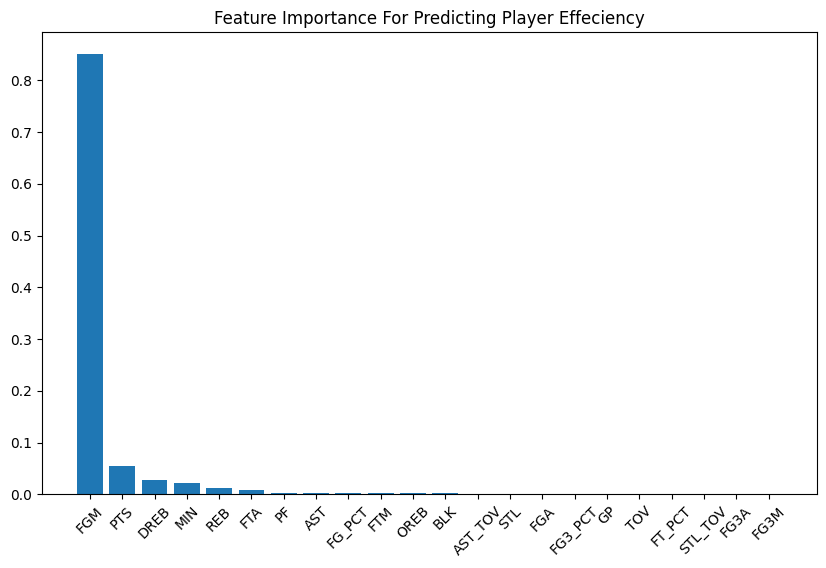

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xticks(rotation = 45)
plt.title("Feature Importance For Predicting Player Effeciency")

plt.show()

# 11. Compare Actual vs. Predicted EFF

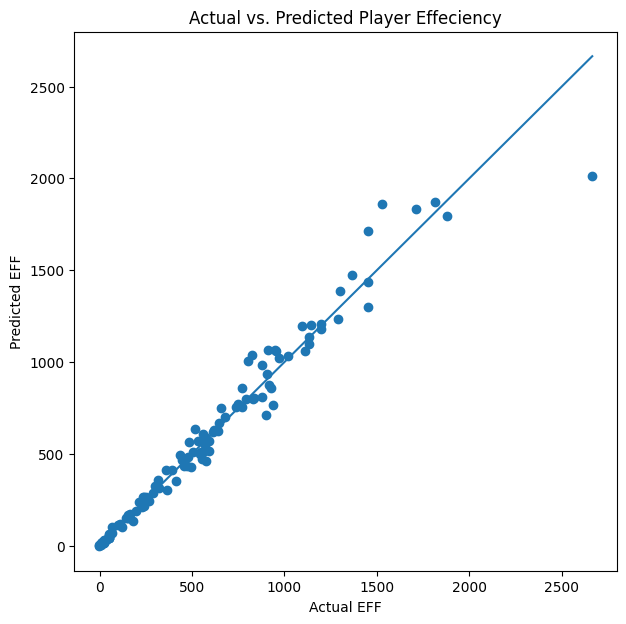

In [ ]:
plt.figure(figsize=(7,7))

plt.scatter(
    y_test,
    predictions
)

plt.xlabel("Actual EFF")
plt.ylabel("Predicted EFF")
plt.title("Actual vs. Predicted Player Effeciency")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.show()

## 12. Predicting All-NBA Team Selection (Classification)

Since the dataset doesn't explicitly contain 'All-NBA Team selection' labels, we will create a proxy target variable. We'll define players in the top 5% of 'EFF' (Player Efficiency Rating) as 'All-NBA' caliber players for the purpose of this classification task. This is a common approach when ground truth labels are unavailable, using a strong performance indicator as a proxy.

In [ ]:
# Calculate the 95th percentile of EFF to define 'All-NBA' players
eff_threshold = df['EFF'].quantile(0.95)
df['is_all_nba'] = (df['EFF'] >= eff_threshold).astype(int)

print(f"EFF threshold for All-NBA: {eff_threshold:.2f}")
print(f"Number of All-NBA players (top 5% by EFF): {df['is_all_nba'].sum()}")

display(df[['PLAYER', 'EFF', 'is_all_nba']].sort_values(by='EFF', ascending=False).head(10))

EFF threshold for All-NBA: 1531.65
Number of All-NBA players (top 5% by EFF): 30


,PLAYER,EFF,is_all_nba
9,Nikola Jokić,2665,1
1,Shai Gilgeous-Alexander,2189,1
0,Luka Dončić,2146,1
17,Jalen Johnson,2094,1
18,Victor Wembanyama,2038,1
3,Kevin Durant,1992,1
22,Karl-Anthony Towns,1963,1
7,Jamal Murray,1947,1
28,Scottie Barnes,1933,1
4,Tyrese Maxey,1893,1


Now we will prepare the data for the classification model. The features will be the same player statistics used for predicting EFF, but the target will be our newly created `is_all_nba` column. We will exclude 'EFF' itself from the features to avoid target leakage.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Define features (excluding 'EFF') and the new target
classification_features = [
    "GP", "MIN", "FGM", "FGA", "FG_PCT", "FG3M", "FG3A", "FG3_PCT",
    "FTM", "FTA", "FT_PCT", "OREB", "DREB", "REB", "AST", "STL",
    "BLK", "TOV", "PF", "PTS", "AST_TOV", "STL_TOV"
]
classification_target = 'is_all_nba'

X_clf = df[classification_features]
y_clf = df[classification_target]

# Split data for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

### Train a Random Forest Classifier

We'll use a Random Forest Classifier to predict whether a player is 'All-NBA' based on their statistics.

In [ ]:
clf_model = RandomForestClassifier(n_estimators=200, random_state=42)
clf_model.fit(X_train_clf, y_train_clf)

RandomForestClassifier(n_estimators=200, random_state=42)

### Evaluate the Classification Model

We'll evaluate the model using a classification report, which includes precision, recall, and F1-score, and a confusion matrix to understand its performance in classifying 'All-NBA' players.

In [ ]:
clf_predictions = clf_model.predict(X_test_clf)

print("Classification Report:")
print(classification_report(y_test_clf, clf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_clf, clf_predictions))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       111
           1       0.75      1.00      0.86         6

    accuracy                           0.98       117
   macro avg       0.88      0.99      0.92       117
weighted avg       0.99      0.98      0.98       117


Confusion Matrix:
[[109   2]
 [  0   6]]


### Visualize Feature Importance for All-NBA Classification

Let's visualize the feature importances from our Random Forest Classifier to understand which player statistics are most predictive of 'All-NBA' selection (based on our EFF-based proxy).

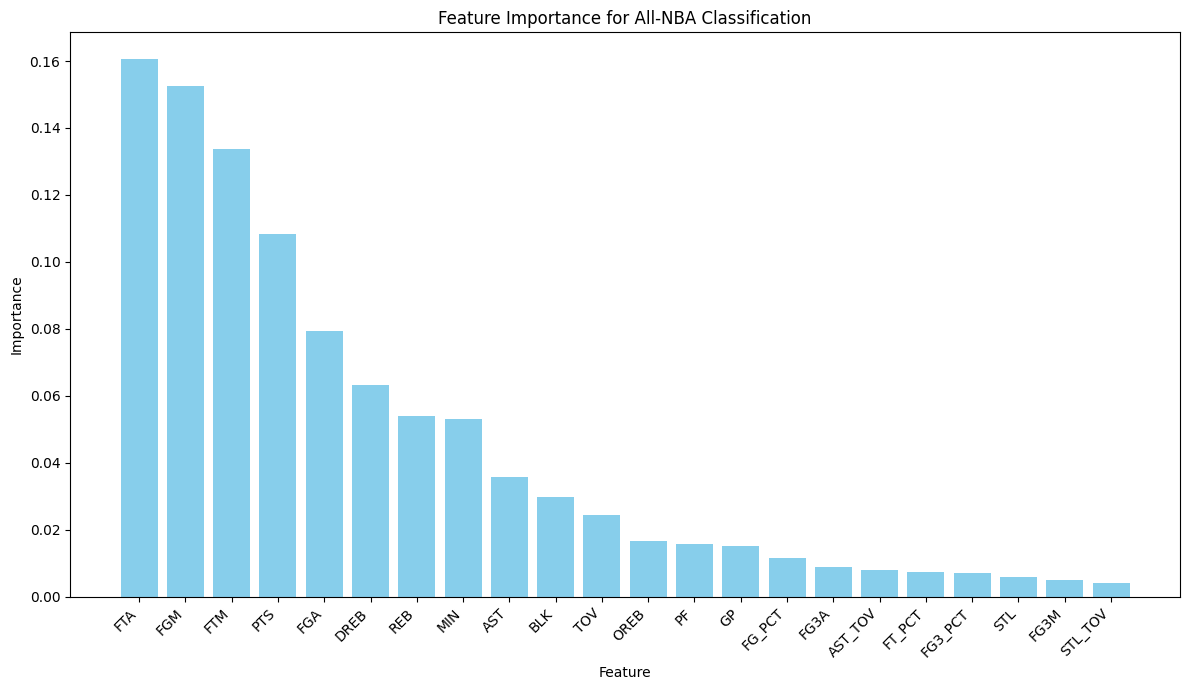

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances from the trained classifier
clf_importance = pd.DataFrame({
    "Feature": X_clf.columns,
    "Importance": clf_model.feature_importances_
})

# Sort features by importance
clf_importance = clf_importance.sort_values(by="Importance", ascending=False)

# Create the plot
plt.figure(figsize=(12, 7))
plt.bar(clf_importance["Feature"], clf_importance["Importance"], color='skyblue')
plt.xticks(rotation=45, ha='right')
plt.title("Feature Importance for All-NBA Classification")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

This bar chart visualizes the feature importances derived from the Random Forest Classifier trained to predict 'All-NBA' status. Each bar represents a player statistic, and its height indicates how much that statistic contributed to the model's prediction. A taller bar means the feature was more influential.

As observed previously, 'FTA' (Free Throw Attempts), 'FGM' (Field Goals Made), 'FTM' (Free Throws Made), and 'PTS' (Points) are among the most important features. This suggests that players who are active in generating scoring opportunities, particularly through free throws and field goals, and those who accumulate more points, are strongly indicative of being in the top tier of players, aligning with our 'All-NBA' proxy definition.

### Visualize a Classification Tree

To understand the decision-making process for classifying 'All-NBA' players, let's train a simple `DecisionTreeClassifier` and visualize its structure. This will show the rules based on player statistics that the tree uses to predict 'All-NBA' status.

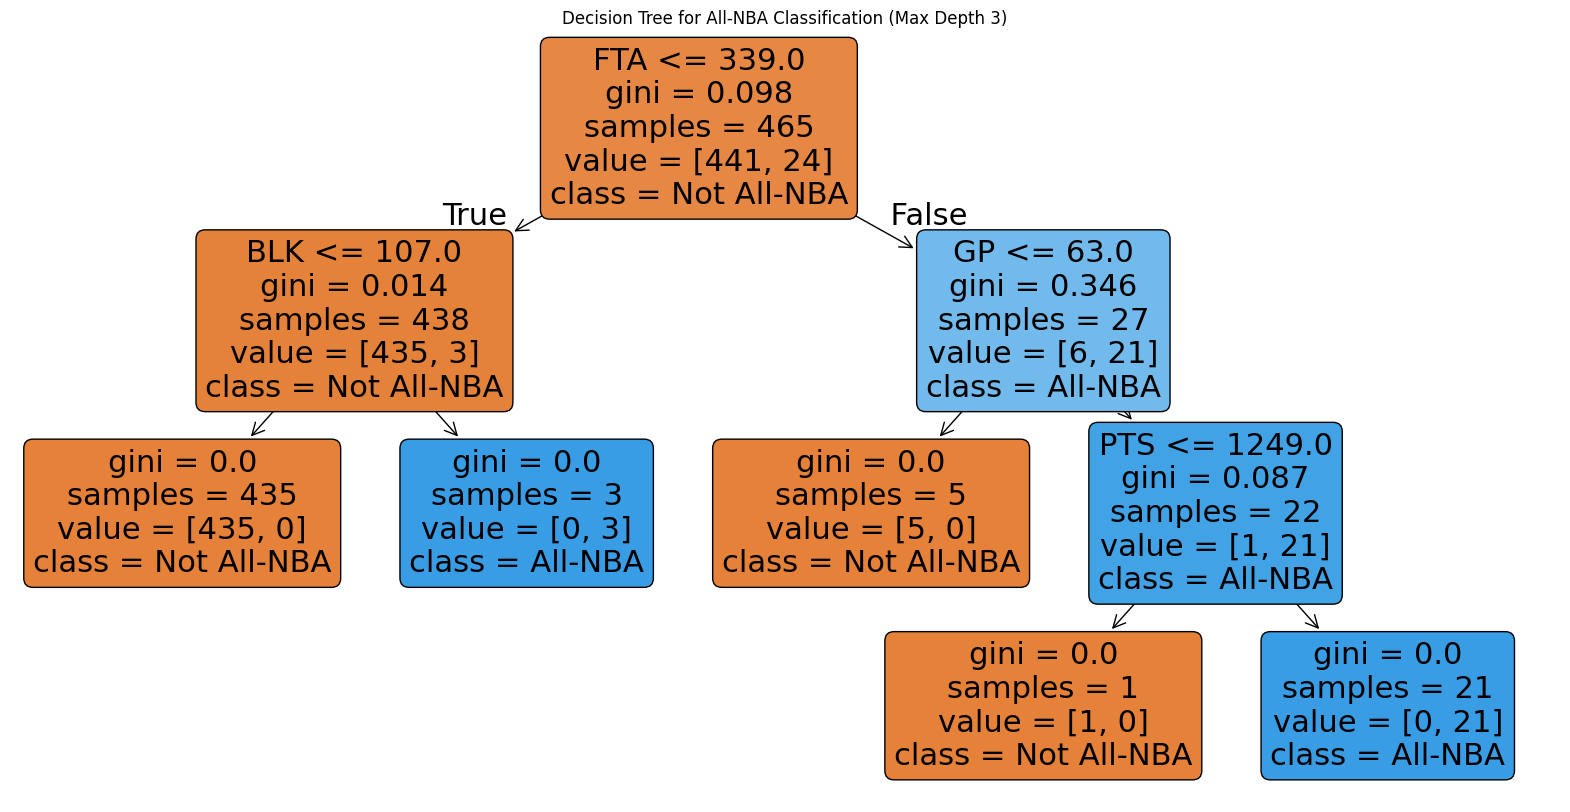

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Train a Decision Tree Classifier
# Limiting max_depth for better visualization of the tree structure
dt_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_clf.fit(X_train_clf, y_train_clf)

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(dt_clf, feature_names=classification_features, class_names=['Not All-NBA', 'All-NBA'], filled=True, rounded=True)
plt.title("Decision Tree for All-NBA Classification (Max Depth 3)")
plt.show()

This image displays a simplified Decision Tree Classifier, limited to a maximum depth of 3 for better interpretability. It illustrates the series of rules the model follows to classify a player as either 'All-NBA' or 'Not All-NBA' based on their statistics.

## 13. Project Conclusion

This project aimed to build models for understanding and predicting NBA player impact, using both regression and classification approaches based on player statistics for the 2025-2026 season.

### Regression Model (Predicting Player Efficiency Rating - EFF)

The Random Forest Regressor demonstrated strong performance in predicting a player's EFF, achieving an R² of approximately 0.96 and an RMSE of around 93.92. This indicates that the model can accurately estimate a player's overall efficiency based on their fundamental statistics. The feature importance analysis revealed that **Field Goals Made (FGM)**, **Points (PTS)**, **Defensive Rebounds (DREB)**, and **Minutes Played (MIN)** were the most significant predictors of EFF. This aligns with intuitive understanding, as scoring, rebounding, and playing time are crucial components of a player's overall impact.

### Classification Model (Predicting 'All-NBA' Caliber Players)

To identify 'All-NBA' caliber players, a proxy target variable was created by labeling players in the top 5% of EFF as 'All-NBA'. A Random Forest Classifier was trained on this task. The model performed exceptionally well, achieving an accuracy of 98% with high precision, recall, and F1-scores, particularly for the 'All-NBA' class (Class 1: Recall 1.00, Precision 0.75, F1-score 0.86). This suggests the model is effective at identifying high-impact players, albeit with some false positives (2 players predicted as All-NBA who were not in the top 5% EFF).

Similar to the regression model, the feature importance for the classification task highlighted **Free Throw Attempts (FTA)**, **Field Goals Made (FGM)**, **Free Throws Made (FTM)**, and **Points (PTS)** as the most influential statistics. This underscores the critical role of offensive output and scoring efficiency in distinguishing top-tier players.

### Overall Insights

Both models consistently point to scoring-related metrics (FGM, PTS, FTA, FTM) as primary drivers of player impact, whether measured by overall efficiency or 'All-NBA' potential. Defensive rebounding and minutes played also contribute significantly to a player's statistical influence. The project successfully demonstrated how machine learning can be leveraged to quantify player value and identify key performance indicators in basketball, offering valuable insights for player evaluation and team building.